# Arch 4 - DeepSeek-style MoE decoder (from scratch, 2x T4)

A small mixture-of-experts language model that borrows the efficiency ideas of DeepSeek-V2/V3, written in plain PyTorch ops
(no model or tokenizer libraries). **222.6M parameters in total, ~81M active per token.**

| DeepSeek idea | What this notebook does with it |
|---|---|
| **MLA** (latent KV compression, decoupled RoPE) | K/V pass through a 192-dim latent; the KV cache stores 208 numbers per token per layer instead of 1344 for full multi-head attention |
| **DeepSeekMoE** | layer 0 dense, layers 1-11 MoE: 32 small routed experts (top-4) + 1 always-on shared expert |
| **Auxiliary-loss-free balancing** (V3) | per-expert routing bias nudged every step from measured load; sigmoid gates; tiny sequence-wise safety loss |
| **Multi-token prediction** (V3) | extra module predicts token t+2 while training (weight 0.3 -> 0.1), dropped at inference |
| **Our adaptation** | fixed-size capacity buffers + one batched matmul across experts: static shapes, `torch.compile`-friendly (verified: single graph, zero breaks), and *drop-free* routing in eval/generation |

Everything else is shared with arch 3: byte-level BPE tokenizer written from scratch, memory-mapped token files, DDP over both T4s,
fp16, fused AdamW, exact resume, and checkpoints pushed to Hugging Face every 250 steps.

**The tokenizer and token files are reused from your arch 3 repo** (`HF_DATA_REPO` in `config.py`) so both models see identical data.
If they are not there, section 6 builds them.

**If Kaggle crashes or times out: press Run All again** - it restores everything from the Hub and continues from the exact step.

Settings: GPU **T4 x2**, Internet **on**, secret `HF` holding a write token.

> **Longer run (from scratch).** This version trains on **600M tokens** (the first run used 100M) with a fresh Hugging Face repo
> (`legal-arch4-moe-v2`), so nothing from the earlier run is restored. It reuses the tokenizer and token files from the arch 3 repo.
> Change `TRAIN_TOKENS` in the config cell (up to 600M) to train longer or shorter; steps, schedule and warm-up follow automatically.


## 1. Setup and Hugging Face login

In [13]:
!pip install -q ijson
import os, sys, json, math, time, gc, zipfile
import torch
from huggingface_hub import login, HfApi, hf_hub_download
from kaggle_secrets import UserSecretsClient

HF_TOKEN = UserSecretsClient().get_secret("HF")
os.environ["HF_TOKEN"] = HF_TOKEN          # child processes (torchrun) read it from here
login(token=HF_TOKEN)

WORK_DIR = "/kaggle/working/arch4"
os.makedirs(WORK_DIR, exist_ok=True)
sys.path.insert(0, WORK_DIR)
print("Logged in to Hugging Face.")

Note: Environment variable`HF_TOKEN` is set and is the current active token independently from the token you've just configured.


Logged in to Hugging Face.


## 2. GPU check

In [14]:
n_gpu = torch.cuda.device_count()
print("CUDA available:", torch.cuda.is_available(), "| GPUs:", n_gpu)
for i in range(n_gpu):
    p = torch.cuda.get_device_properties(i)
    print(f"  GPU {i}: {p.name}, {p.total_memory / 1e9:.1f} GB, compute capability {p.major}.{p.minor}")
if n_gpu < 2:
    print("Only one GPU visible - training still works, it just runs gradient accumulation instead of DDP.")

CUDA available: True | GPUs: 2
  GPU 0: Tesla T4, 15.6 GB, compute capability 7.5
  GPU 1: Tesla T4, 15.6 GB, compute capability 7.5


## 3. Configuration
Every knob lives in `config.py`. Edit it here, then re-run this cell.

In [ ]:
%%writefile /kaggle/working/arch4/config.py
"""
Single place for every knob in the arch-3 pipeline.
All scripts (tokenizer, data prep, model, trainer) import this file.
"""
import os
import json

# ---------------------------------------------------------------- hub / data
HF_DATASET_REPO = "Exploration-Lab/CS-781-Capstone"
HF_MODEL_REPO = "D-240357/legal-arch4-moe-v2"    # NEW repo for the longer run, so nothing from the 100M-token run can be restored by mistake
HF_DATA_REPO = "D-240357/legal-arch3-decoder"    # arch 3 already built the tokenizer + token files: reuse them (same data, fair comparison)
HF_PRIVATE = True

TRAIN_FILES = [
    "Phase_1_Pretraining/Train/train_acts.json",
    "Phase_1_Pretraining/Train/train_high_courts.json",
    "Phase_1_Pretraining/Train/train_supreme_court.json",
    "Phase_1_Pretraining/Train/train_tribunals.json",
]
TEST_FILE = "Phase_1_Pretraining/Test/test.json"

# Relative share of the training text taken from each file above (same order). The corpus is
# interleaved by these weights, so 600M tokens cover all four sources instead of just the first
# files in the list. Weights are by characters; a source that runs out is simply skipped.
SOURCE_WEIGHTS = [1.0, 1.0, 1.0, 1.0]

# ------------------------------------------------------------------- folders
WORK_DIR = "/kaggle/working/arch4"
DATA_DIR = os.path.join(WORK_DIR, "data")
CKPT_DIR = os.path.join(WORK_DIR, "ckpt")
CODE_DIR = WORK_DIR

TOKENIZER_PATH = os.path.join(DATA_DIR, "tokenizer.json")
TRAIN_BIN = os.path.join(DATA_DIR, "train.bin")
VAL_BIN = os.path.join(DATA_DIR, "val.bin")
META_PATH = os.path.join(DATA_DIR, "meta.json")
STATE_PATH = os.path.join(CKPT_DIR, "training_state.pt")
FINAL_PATH = os.path.join(CKPT_DIR, "model_final.pt")
LOG_PATH = os.path.join(CKPT_DIR, "train_log.jsonl")
BEST_PATH = os.path.join(CKPT_DIR, "model_best.pt")     # weights with the lowest validation loss so far

# ----------------------------------------------------------------- tokenizer
VOCAB_SIZE = 32000            # 256 bytes + merges + 2 specials (32000 = 500 * 64, tensor-core friendly)
TOK_SAMPLE_MB_PER_FILE = 40   # text used to learn the merges, taken from each train file
TOK_SAMPLE_STRIDE = 5         # take every 5th doc so the sample spans the whole file

# ---------------------------------------------------------------------- data
# Total tokens to train on (from scratch). The prepared file holds 600M tokens, so anything up to that is a single pass
# with no repeated data. At ~17.9K tok/s on 2xT4: 100M ~ 1.6 h, 400M ~ 6.2 h, 600M ~ 9.3 h (inside the 10.5 h crash guard).
TRAIN_TOKENS = 600_000_000
VAL_TOKENS = 3_000_000
VAL_EVERY_NTH_DOC = 100       # every 100th document is held out for validation
MIN_DOC_CHARS = 100
PREP_WORKERS = max(1, (os.cpu_count() or 2))

# --------------------------------------------------------------------- model
N_LAYER = 12
N_HEAD = 12
D_MODEL = 768
MAX_SEQ_LEN = 2048
ROPE_BASE = 10000.0
NORM_EPS = 1e-5

# Multi-head Latent Attention: per head q/k = 48 (content) + 16 (rotary) dims, v = 64
Q_LORA = 384                  # query bottleneck
KV_LORA = 192                 # KV latent size -> cache holds 192 + 16 numbers per token per layer
QK_NOPE = 48
QK_ROPE = 16
V_DIM = 64

# DeepSeekMoE
N_DENSE_LAYERS = 1            # first layer stays a plain SwiGLU FFN (as in DeepSeek)
D_FF_DENSE = 2048
N_ROUTED = 32                 # small routed experts per MoE layer ...
TOP_K = 4                     # ... of which each token uses 4 ...
EXPERT_FF = 192
SHARED_FF = 512               # ... plus one shared expert every token passes through
CAPACITY_FACTOR = 1.25        # training-time buffer size per expert (eval/generation is drop-free)

# load balancing (aux-loss-free, DeepSeek-V3 style)
BIAS_UPDATE_SPEED = 0.01      # how fast expert biases chase the mean load
BIAS_FREEZE_FRAC = 0.9        # freeze biases for the last 10% of training
SEQ_AUX_ALPHA = 1e-4          # tiny sequence-wise balance loss as a safety net

# multi-token prediction
USE_MTP = True
MTP_FF = 1024
MTP_WEIGHT_EARLY = 0.3
MTP_WEIGHT_LATE = 0.1
MTP_SWITCH_FRAC = 0.67        # fraction of training after which the weight drops to MTP_WEIGHT_LATE

# ------------------------------------------------------------------ training
SEED = 42
MICRO_BATCH = 2               # sequences per GPU per forward pass. 4 ran out of memory on a 15 GB T4 (two fp32 logits tensors + expert buffers)
TOKENS_PER_STEP = 65_536      # global batch; grad-accum is derived from this and the GPU count
PEAK_LR = 4e-4
MIN_LR_RATIO = 0.1
WARMUP_STEPS = 100
WEIGHT_DECAY = 0.1
BETAS = (0.9, 0.95)
MAX_GRAD_NORM = 1.0
Z_LOSS = 1e-4                 # tiny penalty on logsumexp^2, keeps fp16 logits tame

COMPILE = True
ENFORCE_PARAM_BUDGET = True   # capstone rule: 50M-300M parameters
LOG_EVERY = 20
EVAL_EVERY = 250
EVAL_SEQS = 64                # validation sequences per eval (split across GPUs)
CKPT_EVERY = 250              # steps between local save + HF push
SQUASH_EVERY_N_PUSHES = 8     # collapse HF git history now and then so old 1.3 GB copies get freed
TIME_LIMIT_HOURS = 10.5       # counted from trainer start; saves + exits cleanly before Kaggle's 12h wall, just re-run to continue
NCCL_P2P_OFF = True           # P2P between the two T4s hangs on some Kaggle images; comm cost is tiny here

# --------------------------------------------------------------- generation
TARGET_WORDS = 128
MAX_NEW_TOKENS = 384
GEN_TEMPERATURE = 0.7
GEN_TOP_K = 50
GEN_TOP_P = 0.92
N_LOCAL_EVAL = 48              # held-out validation docs used for the local generation check
GEN_BATCH = 8                 # smaller than arch 3: drop-free MoE prefill buffers are big

# Handy for smoke tests: ARCH3_CFG_OVERRIDE='{"N_LAYER": 2, ...}' patches any value above.
_override = os.environ.get("ARCH3_CFG_OVERRIDE")
if _override:
    globals().update(json.loads(_override))

## 4. Restore anything already saved on Hugging Face
On a fresh run this does nothing. After a crash it brings back the tokenizer, token files and the latest checkpoint.

In [16]:
import importlib
import config as C
importlib.reload(C)

for d in (C.DATA_DIR, C.CKPT_DIR):
    os.makedirs(d, exist_ok=True)

api = HfApi()
api.create_repo(C.HF_MODEL_REPO, token=HF_TOKEN, private=C.HF_PRIVATE, exist_ok=True)
on_hub = set(api.list_repo_files(C.HF_MODEL_REPO, token=HF_TOKEN))

def restore(remote_name, local_path, local_dir):
    if os.path.exists(local_path):
        print(f"  have locally: {remote_name}")
    elif remote_name in on_hub:
        print(f"  downloading {remote_name} ...")
        hf_hub_download(C.HF_MODEL_REPO, remote_name, local_dir=local_dir, token=HF_TOKEN)
    else:
        return False
    return True

# 'data/meta.json' is uploaded last, so its presence means the whole data upload finished
def hub_files(repo):
    try:
        return set(api.list_repo_files(repo, token=HF_TOKEN))
    except Exception:
        return set()

data_repo = None
for repo in (C.HF_MODEL_REPO, C.HF_DATA_REPO):
    if "data/meta.json" in hub_files(repo):
        data_repo = repo
        break

if data_repo:
    print(f"  using tokenizer + token files from {data_repo}")
    for name in ("tokenizer.json", "val.bin", "train.bin", "meta.json"):
        local = os.path.join(C.DATA_DIR, name)
        if os.path.exists(local):
            print(f"  have locally: data/{name}")
        else:
            print(f"  downloading data/{name} ...")
            hf_hub_download(data_repo, f"data/{name}", local_dir=C.WORK_DIR, token=HF_TOKEN)
else:
    print("  no prepared data on the hub yet - section 6 will build it")

if restore("training_state.pt", C.STATE_PATH, C.CKPT_DIR):
    restore("train_log.jsonl", C.LOG_PATH, C.CKPT_DIR)
    print("Checkpoint found: training will resume from it.")
else:
    print("No checkpoint yet: training will start from scratch.")

  using tokenizer + token files from D-240357/legal-arch3-decoder
  have locally: data/tokenizer.json
  have locally: data/val.bin
  have locally: data/train.bin
  have locally: data/meta.json
No checkpoint yet: training will start from scratch.


## 5. Tokenizer: byte-level BPE from scratch
Pre-token regex -> UTF-8 bytes -> learned merges. Training works on the table of unique words, which keeps pure Python fast enough.

In [17]:
%%writefile /kaggle/working/arch4/bpe_tokenizer.py
"""
Byte-level BPE tokenizer, written from scratch (stdlib only for the tokenizer logic).

How it works, in short:
  1. A regex chops text into "pre-tokens" (a word with its leading space, a run of digits,
     a run of punctuation, ...). Merges never cross these boundaries.
  2. Every pre-token is turned into raw UTF-8 bytes (ids 0..255), so *any* text can be
     encoded - there is no <unk> and no lowercasing.
  3. Training repeatedly merges the most frequent adjacent id pair into a new id.
     We train on the table of *unique* pre-tokens with their counts, which is what keeps
     it fast in pure Python.
  4. Encoding replays the learned merges (lowest rank first) per pre-token, and caches the
     result, so repeated words cost a single dict lookup.
"""
import re
import json
import heapq
from collections import Counter, defaultdict

# Close to the GPT-2 splitter, but built on plain `re` (no \p{L}), so it needs no extra package.
PRETOKEN_RE = re.compile(
    r"'(?:s|t|re|ve|m|ll|d)| ?[^\W\d_]+| ?\d+| ?[^\s\w]+|\s+(?!\S)|\s+",
    re.UNICODE,
)

EOS_TOKEN = "<|endoftext|>"
PAD_TOKEN = "<|pad|>"


class ByteBPE:
    def __init__(self, merges=None, vocab_size=32000):
        self.vocab_size = vocab_size
        self.merges = [tuple(m) for m in (merges or [])]      # merge i creates id 256 + i
        self.eos_id = vocab_size - 2
        self.pad_id = vocab_size - 1
        self._cache = {}
        self._rebuild_tables()

    # ------------------------------------------------------------- internals
    def _rebuild_tables(self):
        self.ranks = {pair: (i, 256 + i) for i, pair in enumerate(self.merges)}
        vocab = [bytes([i]) for i in range(256)]
        for a, b in self.merges:
            vocab.append(vocab[a] + vocab[b])
        self.vocab = vocab
        self._cache.clear()

    # -------------------------------------------------------------- training
    @classmethod
    def train(cls, texts, vocab_size=32000, log_every=2000):
        """Learn merges from an iterable of strings."""
        n_merges = vocab_size - 256 - 2          # leave room for the two special tokens
        word_counts = Counter()
        for text in texts:
            word_counts.update(PRETOKEN_RE.findall(text))
        print(f"  unique pre-tokens: {len(word_counts):,}")

        words = [list(w.encode("utf-8")) for w in word_counts]
        freqs = list(word_counts.values())
        del word_counts

        pair_count = defaultdict(int)
        where = defaultdict(set)                 # pair -> indices of words that (may) contain it
        for wi, w in enumerate(words):
            f = freqs[wi]
            for pair in zip(w, w[1:]):
                pair_count[pair] += f
                where[pair].add(wi)

        # Max-heap with lazy invalidation: stale entries are fixed up when they surface.
        heap = [(-c, p) for p, c in pair_count.items()]
        heapq.heapify(heap)

        merges = []
        vocab = [bytes([i]) for i in range(256)]
        for m in range(n_merges):
            best = None
            while heap:
                neg, pair = heapq.heappop(heap)
                real = pair_count.get(pair, 0)
                if real <= 0:
                    continue
                if real != -neg:
                    heapq.heappush(heap, (-real, pair))
                    continue
                best = pair
                break
            if best is None:
                print(f"  ran out of pairs after {m} merges")
                break

            new_id = 256 + m
            merges.append(best)
            a, b = best
            vocab.append(vocab[a] + vocab[b])
            touched = {}
            for wi in where.pop(best, ()):
                w = words[wi]
                f = freqs[wi]
                # find the occurrences in this word (left to right, non-overlapping)
                if len(w) < 2:
                    continue
                i, out, changed = 0, [], False
                while i < len(w):
                    if i < len(w) - 1 and w[i] == a and w[i + 1] == b:
                        out.append(new_id)
                        i += 2
                        changed = True
                    else:
                        out.append(w[i])
                        i += 1
                if not changed:
                    continue                      # stale entry in `where`
                for pair in zip(w, w[1:]):        # take the old word's pairs away ...
                    pair_count[pair] -= f
                for pair in zip(out, out[1:]):    # ... and add the new word's pairs
                    pair_count[pair] += f
                    where[pair].add(wi)
                    touched[pair] = pair_count[pair]
                words[wi] = out
            for pair, c in touched.items():
                if c > 0:
                    heapq.heappush(heap, (-c, pair))
            pair_count.pop(best, None)

            if (m + 1) % log_every == 0:
                print(f"  merge {m + 1:,}/{n_merges:,}  last = {vocab[-1]!r}")

        return cls(merges, vocab_size)

    # -------------------------------------------------------------- encoding
    def _encode_word(self, word):
        ids = list(word.encode("utf-8"))
        ranks = self.ranks
        while len(ids) > 1:
            best_rank, best_pair, best_new = None, None, None
            for pair in zip(ids, ids[1:]):
                hit = ranks.get(pair)
                if hit is not None and (best_rank is None or hit[0] < best_rank):
                    best_rank, best_pair, best_new = hit[0], pair, hit[1]
            if best_pair is None:
                break
            a, b = best_pair
            out, i = [], 0
            while i < len(ids):
                if i < len(ids) - 1 and ids[i] == a and ids[i + 1] == b:
                    out.append(best_new)
                    i += 2
                else:
                    out.append(ids[i])
                    i += 1
            ids = out
        return ids

    def encode(self, text):
        cache = self._cache
        if len(cache) > 1_000_000:               # keep RAM bounded on huge corpora
            cache.clear()
        out = []
        for word in PRETOKEN_RE.findall(text):
            ids = cache.get(word)
            if ids is None:
                ids = cache[word] = self._encode_word(word)
            out.extend(ids)
        return out

    def decode(self, ids):
        specials = (self.eos_id, self.pad_id)
        data = b"".join(self.vocab[i] for i in ids if i < len(self.vocab) and i not in specials)
        return data.decode("utf-8", errors="replace")

    # ----------------------------------------------------------- persistence
    def save(self, path):
        with open(path, "w", encoding="utf-8") as f:
            json.dump({"vocab_size": self.vocab_size, "merges": self.merges,
                       "eos": EOS_TOKEN, "pad": PAD_TOKEN}, f)

    @classmethod
    def load(cls, path):
        with open(path, "r", encoding="utf-8") as f:
            blob = json.load(f)
        return cls(blob["merges"], blob["vocab_size"])

Overwriting /kaggle/working/arch4/bpe_tokenizer.py


## 6. Data prep: train the tokenizer, tokenize 600M tokens, mirror to the Hub
Uses every CPU core. Skipped automatically when the files are already there.

In [18]:
%%writefile /kaggle/working/arch4/prep_data.py
"""
One-off data preparation (skipped automatically for anything already on disk):

  1. learn the byte-level BPE merges from a spread-out sample of the training text
  2. tokenize the corpus with all CPU cores into flat uint16 files (train.bin / val.bin)
  3. mirror tokenizer + bins to the Hugging Face repo so a Kaggle restart never repeats this

Training later memory-maps those files, so RAM usage during training stays tiny.
"""
import os
import sys
import json
import time
from collections import deque
from multiprocessing import Pool

import numpy as np
import ijson
from huggingface_hub import hf_hub_download, HfApi

sys.path.insert(0, os.path.dirname(os.path.abspath(__file__)))
import config as C
from bpe_tokenizer import ByteBPE

TOKEN = os.environ.get("HF_TOKEN")


def local_train_files():
    paths = []
    for name in C.TRAIN_FILES:
        paths.append(hf_hub_download(C.HF_DATASET_REPO, name, repo_type="dataset", token=TOKEN))
    return paths


def iter_texts(path):
    """Stream the 'text' field of every record without loading the whole json file."""
    with open(path, "rb") as f:
        for rec in ijson.items(f, "item"):
            text = rec.get("text", "")
            if len(text) >= C.MIN_DOC_CHARS:
                yield text


# ------------------------------------------------------------------ stage 1
def tokenizer_sample(paths):
    budget = C.TOK_SAMPLE_MB_PER_FILE * 1_000_000
    for p in paths:
        used = 0
        for i, text in enumerate(iter_texts(p)):
            if i % C.TOK_SAMPLE_STRIDE:
                continue
            yield text
            used += len(text)
            if used >= budget:
                break
        print(f"  sampled {used / 1e6:.0f} MB from {os.path.basename(p)}", flush=True)


def train_tokenizer(paths):
    print("[1/2] Training BPE tokenizer ...", flush=True)
    t0 = time.time()
    tok = ByteBPE.train(tokenizer_sample(paths), vocab_size=C.VOCAB_SIZE)
    tok.save(C.TOKENIZER_PATH)
    print(f"  done in {(time.time() - t0) / 60:.1f} min, {len(tok.merges):,} merges", flush=True)


# ------------------------------------------------------------------ stage 2
_tok = None


def _init_worker(path):
    global _tok
    _tok = ByteBPE.load(path)


def _encode_batch(batch):
    """batch: list of (is_val, text). Every doc is stored as <eos> + tokens."""
    train, val = [], []
    for is_val, text in batch:
        ids = [_tok.eos_id]
        ids.extend(_tok.encode(text))
        (val if is_val else train).append(np.asarray(ids, dtype=np.uint16))
    cat = lambda xs: np.concatenate(xs) if xs else np.empty(0, dtype=np.uint16)
    return cat(train), cat(val)


def interleaved_texts(paths, weights):
    """
    Walk all source files at once and always pull the next document from the source that is
    furthest behind its weighted share (measured in characters). A source that ends is dropped.
    """
    streams = [iter_texts(p) for p in paths]
    taken = [0.0] * len(paths)
    alive = [True] * len(paths)
    while any(alive):
        i = min((j for j in range(len(paths)) if alive[j]), key=lambda j: taken[j] / weights[j])
        try:
            text = next(streams[i])
        except StopIteration:
            alive[i] = False
            print(f"  source exhausted: {os.path.basename(paths[i])}", flush=True)
            continue
        taken[i] += len(text)
        yield text


def doc_batches(paths, max_chars=2_000_000):
    batch, chars, n = [], 0, 0
    for text in interleaved_texts(paths, C.SOURCE_WEIGHTS):
        batch.append((n % C.VAL_EVERY_NTH_DOC == 0, text))
        chars += len(text)
        n += 1
        if chars >= max_chars:
            yield batch
            batch, chars = [], 0
    if batch:
        yield batch


def tokenize_corpus(paths):
    print(f"[2/2] Tokenizing with {C.PREP_WORKERS} workers -> {C.TRAIN_TOKENS / 1e6:.0f}M train tokens", flush=True)
    t0 = time.time()
    n_train = n_val = 0
    next_report = 20_000_000
    window = 3 * C.PREP_WORKERS               # keep only a few batches in flight -> bounded RAM

    with open(C.TRAIN_BIN, "wb") as ftrain, open(C.VAL_BIN, "wb") as fval, \
            Pool(C.PREP_WORKERS, initializer=_init_worker, initargs=(C.TOKENIZER_PATH,)) as pool:

        def absorb(result):
            nonlocal n_train, n_val, next_report
            tr, va = result.get()
            if n_val < C.VAL_TOKENS and len(va):
                va = va[: C.VAL_TOKENS - n_val]
                fval.write(va.tobytes())
                n_val += len(va)
            if n_train < C.TRAIN_TOKENS + 1 and len(tr):
                tr = tr[: C.TRAIN_TOKENS + 1 - n_train]     # +1 so the last block has a target
                ftrain.write(tr.tobytes())
                n_train += len(tr)
            if n_train >= next_report:
                rate = n_train / (time.time() - t0)
                eta = (C.TRAIN_TOKENS - n_train) / max(rate, 1) / 60
                print(f"  {n_train / 1e6:6.0f}M tokens | {rate / 1e3:.0f}K tok/s | eta {eta:.1f} min", flush=True)
                next_report += 20_000_000

        pending = deque()
        for batch in doc_batches(paths):
            pending.append(pool.apply_async(_encode_batch, (batch,)))
            if len(pending) >= window:
                absorb(pending.popleft())
            if n_train >= C.TRAIN_TOKENS + 1:
                break
        while pending and n_train < C.TRAIN_TOKENS + 1:
            absorb(pending.popleft())
        pool.terminate()

    if n_train < C.TRAIN_TOKENS:
        print(f"  WARNING: corpus only yielded {n_train:,} tokens; training will loop over it.", flush=True)
    meta = {"train_tokens": n_train, "val_tokens": n_val, "vocab_size": C.VOCAB_SIZE, "dtype": "uint16"}
    with open(C.META_PATH, "w") as f:
        json.dump(meta, f)
    print(f"  finished in {(time.time() - t0) / 60:.1f} min: {n_train:,} train / {n_val:,} val tokens", flush=True)


# ------------------------------------------------------------------- hub
def mirror_to_hub():
    api = HfApi()
    api.create_repo(C.HF_MODEL_REPO, token=TOKEN, private=C.HF_PRIVATE, exist_ok=True)
    # meta goes last: its presence on the hub means the whole upload finished
    for local in (C.TOKENIZER_PATH, C.VAL_BIN, C.TRAIN_BIN, C.META_PATH):
        name = "data/" + os.path.basename(local)
        print(f"  uploading {name} ...", flush=True)
        api.upload_file(path_or_fileobj=local, path_in_repo=name, repo_id=C.HF_MODEL_REPO, token=TOKEN)


def main():
    os.makedirs(C.DATA_DIR, exist_ok=True)
    have_bins = all(os.path.exists(p) for p in (C.TRAIN_BIN, C.VAL_BIN, C.META_PATH, C.TOKENIZER_PATH))
    if have_bins:
        print("Tokenizer and token files already present - nothing to do.")
        return
    paths = local_train_files()
    if not os.path.exists(C.TOKENIZER_PATH):
        train_tokenizer(paths)
    tokenize_corpus(paths)
    print("Mirroring to Hugging Face ...", flush=True)
    mirror_to_hub()
    print("Data prep complete.")


if __name__ == "__main__":
    main()

Overwriting /kaggle/working/arch4/prep_data.py


In [19]:
import subprocess
rc = subprocess.run([sys.executable, "prep_data.py"], cwd=WORK_DIR).returncode
assert rc == 0, "data prep failed - read the log above"

Tokenizer and token files already present - nothing to do.


## 7. Tokenizer sanity check

In [20]:
import numpy as np
from bpe_tokenizer import ByteBPE

tok = ByteBPE.load(C.TOKENIZER_PATH)
sample = "The Hon'ble Supreme Court held that Section 438 of the Cr.P.C. does not apply; see (2013) 5 SCC 1."
ids = tok.encode(sample)
assert tok.decode(ids) == sample, "round-trip failed"
print(f"vocab {tok.vocab_size} | eos {tok.eos_id} | pad {tok.pad_id}")
print(f"{len(sample)} chars -> {len(ids)} tokens:", [tok.vocab[i].decode('utf-8', 'replace') for i in ids[:14]], "...")

meta = json.load(open(C.META_PATH))
train = np.memmap(C.TRAIN_BIN, dtype=np.uint16, mode="r")
print(f"train tokens: {meta['train_tokens']:,} | val tokens: {meta['val_tokens']:,} | max id {int(train[:5_000_000].max())}")
print("first tokens decoded:", repr(tok.decode(train[:60].tolist())))

vocab 32000 | eos 31998 | pad 31999
98 chars -> 30 tokens: ['The', ' Hon', "'", 'ble', ' Supreme', ' Court', ' held', ' that', ' Section', ' 438', ' of', ' the', ' Cr', '.'] ...
train tokens: 600,000,001 | val tokens: 3,000,000 | max id 31998
first tokens decoded: 'Court No. - 24 Case :- SECOND APPEAL No. - 550 of 1986 Appellant :- Ram Naresh Singh Baghel Respondent :- Nagar Maha Palika Lko.\n\nCounsel for Appellant :- K.C.Jauhari,Manish Jauhari,Mohit Jauhari,Raj Kumar Srivastava,Ram Bali Ram,V'


## 8. Model
MLA attention + DeepSeekMoE layers + MTP head. Training uses fixed-size expert buffers; inference is drop-free and uses a latent KV cache.

In [21]:
%%writefile /kaggle/working/arch4/model.py
"""
Arch 4: a small DeepSeek-V3-flavoured mixture-of-experts decoder, written from scratch.

Ideas borrowed from the DeepSeek papers (scaled down to ~217M total / ~80M active parameters):

  * MLA - Multi-head Latent Attention. Keys/values are squeezed through a small latent vector,
    so the KV cache holds `kv_lora + qk_rope` numbers per token instead of full K and V.
    RoPE lives on a small separate slice of each head ("decoupled RoPE") so the latent stays
    position-free.
  * DeepSeekMoE - many small routed experts plus one shared expert that every token uses.
  * Auxiliary-loss-free load balancing (V3) - a per-expert bias is added to the routing scores
    *only to pick the top-k*; after every optimizer step it is nudged up for under-used experts
    and down for over-used ones. Gate weights come from the un-biased sigmoid scores. A tiny
    sequence-wise balance loss is kept only as a safety net.
  * Multi-token prediction (MTP) - during training an extra light module predicts the token two
    steps ahead. It shares the embedding / output head and is simply unused at inference.

Our own adaptation: expert dispatch uses fixed-size capacity buffers and one batched matmul over
all experts. Every tensor shape is static, so torch.compile can fuse it and there is no Python
loop over experts. In eval / generation the capacity is raised so that no token is ever dropped.
"""
import math
from dataclasses import dataclass

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.distributed as dist


@dataclass
class ModelConfig:
    vocab_size: int = 32000
    n_layer: int = 12
    n_head: int = 12
    d_model: int = 768
    max_seq_len: int = 2048
    rope_base: float = 10000.0
    norm_eps: float = 1e-5
    # MLA
    q_lora: int = 384
    kv_lora: int = 192
    qk_nope: int = 48
    qk_rope: int = 16
    v_dim: int = 64
    # MoE
    n_dense_layers: int = 1
    d_ff_dense: int = 2048
    n_routed: int = 32
    top_k: int = 4
    expert_ff: int = 192
    shared_ff: int = 512
    capacity_factor: float = 1.25
    # multi-token prediction
    mtp: bool = True
    mtp_ff: int = 1024


# ---------------------------------------------------------------------------
# small building blocks
# ---------------------------------------------------------------------------
class RMSNorm(nn.Module):
    def __init__(self, dim, eps):
        super().__init__()
        self.eps = eps
        self.weight = nn.Parameter(torch.ones(dim))

    def forward(self, x):
        x32 = x.float()
        x32 = x32 * torch.rsqrt(x32.pow(2).mean(-1, keepdim=True) + self.eps)
        return (x32 * self.weight).to(x.dtype)


def build_rope_cache(dim, max_len, base):
    inv_freq = 1.0 / (base ** (torch.arange(0, dim, 2).float() / dim))
    angles = torch.outer(torch.arange(max_len).float(), inv_freq)
    return angles.cos(), angles.sin()


def apply_rope(x, cos, sin):
    x1, x2 = x.float().chunk(2, dim=-1)
    return torch.cat([x1 * cos - x2 * sin, x2 * cos + x1 * sin], dim=-1).to(x.dtype)


class SwiGLU(nn.Module):
    def __init__(self, d_model, hidden):
        super().__init__()
        self.gate_up = nn.Linear(d_model, 2 * hidden, bias=False)
        self.down = nn.Linear(hidden, d_model, bias=False)

    def forward(self, x):
        gate, up = self.gate_up(x).chunk(2, dim=-1)
        return self.down(F.silu(gate) * up)


# ---------------------------------------------------------------------------
# Multi-head Latent Attention
# ---------------------------------------------------------------------------
class MLA(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.H = cfg.n_head
        self.nope, self.rope, self.vd = cfg.qk_nope, cfg.qk_rope, cfg.v_dim
        self.kv_lora = cfg.kv_lora

        self.q_down = nn.Linear(cfg.d_model, cfg.q_lora, bias=False)
        self.q_norm = RMSNorm(cfg.q_lora, cfg.norm_eps)
        self.q_up = nn.Linear(cfg.q_lora, self.H * (self.nope + self.rope), bias=False)

        # one projection yields the compressed KV latent AND the (shared) rotary key slice
        self.kv_down = nn.Linear(cfg.d_model, cfg.kv_lora + self.rope, bias=False)
        self.kv_norm = RMSNorm(cfg.kv_lora, cfg.norm_eps)
        self.kv_up = nn.Linear(cfg.kv_lora, self.H * (self.nope + self.vd), bias=False)

        self.out = nn.Linear(self.H * self.vd, cfg.d_model, bias=False)

    def forward(self, x, cos, sin, past=None, key_mask=None):
        B, T, _ = x.shape
        H = self.H

        q = self.q_up(self.q_norm(self.q_down(x))).view(B, T, H, self.nope + self.rope).transpose(1, 2)
        q_nope, q_rope = q.split([self.nope, self.rope], dim=-1)
        q_rope = apply_rope(q_rope, cos, sin)

        kv = self.kv_down(x)
        latent, k_rope = kv.split([self.kv_lora, self.rope], dim=-1)
        latent = self.kv_norm(latent)                                   # (B, T, kv_lora)
        k_rope = apply_rope(k_rope.unsqueeze(1), cos, sin)              # (B, 1, T, rope) shared by all heads

        if past is not None:                                            # cache = latent + rope key only
            latent = torch.cat([past[0], latent], dim=1)
            k_rope = torch.cat([past[1], k_rope], dim=2)
        present = (latent, k_rope)

        S = latent.size(1)
        kv_full = self.kv_up(latent).view(B, S, H, self.nope + self.vd).transpose(1, 2)
        k_nope, v = kv_full.split([self.nope, self.vd], dim=-1)

        q = torch.cat([q_nope, q_rope], dim=-1)
        k = torch.cat([k_nope, k_rope.expand(-1, H, -1, -1)], dim=-1)

        if key_mask is None:
            o = F.scaled_dot_product_attention(q, k, v, is_causal=True)
        else:
            o = F.scaled_dot_product_attention(q, k, v, attn_mask=key_mask)
        o = o.transpose(1, 2).reshape(B, T, H * self.vd)
        return self.out(o), present


# ---------------------------------------------------------------------------
# DeepSeekMoE layer with auxiliary-loss-free balancing and static-shape dispatch
# ---------------------------------------------------------------------------
@torch.compiler.disable
def _slot_positions(eid, E):
    """
    For every (token, expert) pair: its running position inside that expert's buffer, plus the
    one-hot assignment matrix. This is integer bookkeeping on ~33K elements, so it runs eagerly
    on purpose: comparing an index tensor with arange(E) trips an Inductor/Triton codegen bug on
    some torch builds (seen on Kaggle). Everything heavy around it stays compiled.
    """
    onehot = (eid.unsqueeze(1) == torch.arange(E, device=eid.device).unsqueeze(0)).to(torch.int32)
    pos = onehot.cumsum(0).gather(1, eid.unsqueeze(1)).squeeze(1) - 1
    return onehot, pos


class MoE(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.E, self.K = cfg.n_routed, cfg.top_k
        self.cap_factor = cfg.capacity_factor
        D, h = cfg.d_model, cfg.expert_ff

        self.router = nn.Linear(D, self.E, bias=False)
        self.w_gate_up = nn.Parameter(torch.empty(self.E, D, 2 * h))    # all experts stacked -> one bmm
        self.w_down = nn.Parameter(torch.empty(self.E, h, D))
        self.shared = SwiGLU(D, cfg.shared_ff)

        nn.init.normal_(self.w_gate_up, std=0.02)
        nn.init.normal_(self.w_down, std=0.02)

        self.register_buffer("bias", torch.zeros(self.E))               # saved: it is learned state
        self.register_buffer("load", torch.zeros(self.E), persistent=False)
        self.register_buffer("dropped", torch.zeros(()), persistent=False)

    def forward(self, x):
        B, T, D = x.shape
        N, E, K = B * T, self.E, self.K
        flat = x.reshape(N, D)

        # --- routing: sigmoid affinities, biased top-k, normalised gate weights
        scores = torch.sigmoid(F.linear(flat.float(), self.router.weight.float()))      # (N, E)
        _, idx = torch.topk(scores.detach() + self.bias, K, dim=-1)                     # bias steers selection only
        gate = scores.gather(1, idx)
        gate = gate / (gate.sum(-1, keepdim=True) + 1e-9)

        # --- slot assignment: position of every (token, expert) pair inside its expert's buffer
        eid = idx.reshape(-1)                                                           # token-major, (N*K,)
        onehot, pos = _slot_positions(eid, E)

        if self.training:
            cap = int(math.ceil(N * K / E * self.cap_factor / 8) * 8)
        else:
            cap = N                                                                     # drop-free for eval / generation
        keep = pos < cap
        slot = torch.where(keep, eid * cap + pos, torch.full_like(eid, E * cap))        # overflow -> spare row

        # --- dispatch -> one batched matmul over all experts -> combine
        dt = torch.get_autocast_dtype("cuda") if (torch.is_autocast_enabled() and x.is_cuda) else x.dtype
        xs = flat.to(dt).repeat_interleave(K, dim=0)
        buf = xs.new_zeros(E * cap + 1, D).index_put((slot,), xs)
        hid = buf[: E * cap].view(E, cap, D)
        g, u = torch.bmm(hid, self.w_gate_up.to(dt)).chunk(2, dim=-1)
        y = torch.bmm(F.silu(g) * u, self.w_down.to(dt))                                # (E, cap, D)
        y = torch.cat([y.reshape(E * cap, D), y.new_zeros(1, D)], dim=0)
        routed = (y[slot].view(N, K, D) * gate.to(y.dtype).unsqueeze(-1)).sum(1)

        out = (routed.to(x.dtype) + self.shared(flat)).view(B, T, D)

        if not self.training:
            return out, x.new_zeros((), dtype=torch.float32)

        # --- bookkeeping for balancing (no gradient) and the small sequence-wise safety loss
        with torch.no_grad():
            self.load += onehot.sum(0).float()
            self.dropped += (~keep).sum().float()
        p = (scores / (scores.sum(-1, keepdim=True) + 1e-9)).view(B, T, E).mean(1)      # mean affinity per sequence
        f = E * onehot.view(B, T * K, E).float().mean(1)                                # share of assignments per expert
        aux = (f * p).sum(-1).mean()
        return out, aux


# ---------------------------------------------------------------------------
# transformer block, MTP head, full model
# ---------------------------------------------------------------------------
class Block(nn.Module):
    def __init__(self, cfg, use_moe):
        super().__init__()
        self.attn_norm = RMSNorm(cfg.d_model, cfg.norm_eps)
        self.attn = MLA(cfg)
        self.ffn_norm = RMSNorm(cfg.d_model, cfg.norm_eps)
        self.use_moe = use_moe
        self.ffn = MoE(cfg) if use_moe else SwiGLU(cfg.d_model, cfg.d_ff_dense)

    def forward(self, x, cos, sin, past=None, key_mask=None):
        a, present = self.attn(self.attn_norm(x), cos, sin, past, key_mask)
        x = x + a
        if self.use_moe:
            f, aux = self.ffn(self.ffn_norm(x))
        else:
            f, aux = self.ffn(self.ffn_norm(x)), x.new_zeros((), dtype=torch.float32)
        return x + f, present, aux


class MTPHead(nn.Module):
    """Predicts token t+2 from (trunk hidden state at t, embedding of token t+1)."""

    def __init__(self, cfg):
        super().__init__()
        self.norm_h = RMSNorm(cfg.d_model, cfg.norm_eps)
        self.norm_e = RMSNorm(cfg.d_model, cfg.norm_eps)
        self.proj = nn.Linear(2 * cfg.d_model, cfg.d_model, bias=False)
        self.attn_norm = RMSNorm(cfg.d_model, cfg.norm_eps)
        self.attn = MLA(cfg)
        self.ffn_norm = RMSNorm(cfg.d_model, cfg.norm_eps)
        self.ffn = SwiGLU(cfg.d_model, cfg.mtp_ff)

    def forward(self, h, next_emb, cos, sin):
        z = self.proj(torch.cat([self.norm_h(h), self.norm_e(next_emb)], dim=-1))
        a, _ = self.attn(self.attn_norm(z), cos, sin)
        z = z + a
        return z + self.ffn(self.ffn_norm(z))


class MoEGPT(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.cfg = cfg
        self.tok_emb = nn.Embedding(cfg.vocab_size, cfg.d_model)
        self.blocks = nn.ModuleList([Block(cfg, use_moe=i >= cfg.n_dense_layers) for i in range(cfg.n_layer)])
        self.final_norm = RMSNorm(cfg.d_model, cfg.norm_eps)
        self.mtp_head = MTPHead(cfg) if cfg.mtp else None

        cos, sin = build_rope_cache(cfg.qk_rope, cfg.max_seq_len, cfg.rope_base)
        self.register_buffer("rope_cos", cos, persistent=False)
        self.register_buffer("rope_sin", sin, persistent=False)

        self.apply(self._init_weights)
        scale = 0.02 / math.sqrt(2 * cfg.n_layer)                       # GPT-2 style residual-branch scaling
        for blk in self.blocks:
            nn.init.normal_(blk.attn.out.weight, std=scale)
            if blk.use_moe:
                nn.init.normal_(blk.ffn.w_down, std=scale)
                nn.init.normal_(blk.ffn.shared.down.weight, std=scale)
            else:
                nn.init.normal_(blk.ffn.down.weight, std=scale)

    @staticmethod
    def _init_weights(m):
        if isinstance(m, (nn.Linear, nn.Embedding)):
            nn.init.normal_(m.weight, std=0.02)

    # ---- bookkeeping -------------------------------------------------------
    def num_params(self):
        return sum(p.numel() for p in self.parameters())

    def active_params(self):
        """Parameters touched per token: everything except the routed experts that were not picked."""
        total = self.num_params()
        routed = sum(b.ffn.w_gate_up.numel() + b.ffn.w_down.numel() for b in self.blocks if b.use_moe)
        inactive = routed * (1 - self.cfg.top_k / self.cfg.n_routed)
        mtp = sum(p.numel() for p in self.mtp_head.parameters()) if self.mtp_head is not None else 0
        return int(total - inactive - mtp)                              # MTP is training-only

    @torch.no_grad()
    def update_balance(self, speed):
        """
        Aux-loss-free balancing step (call once per optimizer step on every rank):
        push each expert's routing bias toward the mean load, then reset the counters.
        Returns (max load violation, fraction of assignments dropped) for logging.
        """
        moes = [b.ffn for b in self.blocks if b.use_moe]
        load = torch.stack([m.load for m in moes])
        dropped = torch.stack([m.dropped for m in moes])
        if dist.is_available() and dist.is_initialized():
            dist.all_reduce(load)
            dist.all_reduce(dropped)
        mean = load.mean(dim=-1, keepdim=True)
        if speed > 0:
            step = speed * torch.sign(mean - load)                      # under-used experts get a boost
            for m, s in zip(moes, step):
                m.bias += s
        maxvio = ((load - mean).abs().amax(dim=-1) / mean.squeeze(-1).clamp(min=1)).mean()
        drop_frac = dropped.sum() / load.sum().clamp(min=1)
        for m in moes:
            m.load.zero_()
            m.dropped.zero_()
        return maxvio, drop_frac

    def hidden_states(self, idx):
        """Final-layer hidden states (B, T, d_model) - what a Phase 2-7 task head sits on top of."""
        B, T = idx.shape
        cos = self.rope_cos[:T]
        sin = self.rope_sin[:T]
        x = self.tok_emb(idx)
        for blk in self.blocks:
            x, _, _ = blk(x, cos, sin)
        return self.final_norm(x)

    # ---- forward -----------------------------------------------------------
    def forward(self, idx, targets=None, caches=None, start_pos=0, key_mask=None, last_only=False):
        """
        Training:   model(idx, targets) -> (ce, mtp_ce, seq_aux, z_loss)
        Inference:  model(idx, caches=..., ...) -> (logits, new_caches)
        """
        B, T = idx.shape
        cos = self.rope_cos[start_pos:start_pos + T]
        sin = self.rope_sin[start_pos:start_pos + T]

        x = self.tok_emb(idx)
        new_caches, aux_total = [], x.new_zeros((), dtype=torch.float32)
        for i, blk in enumerate(self.blocks):
            past = caches[i] if caches is not None else None
            x, present, aux = blk(x, cos, sin, past, key_mask)
            new_caches.append(present)
            aux_total = aux_total + aux

        hidden = x
        x = self.final_norm(x)
        if last_only:
            x = x[:, -1:, :]
        logits = F.linear(x, self.tok_emb.weight)

        if targets is None:
            return logits, new_caches

        V = logits.size(-1)
        logits = logits.float()
        ce = F.cross_entropy(logits.view(-1, V), targets.reshape(-1))
        z = torch.logsumexp(logits, dim=-1).pow(2).mean()

        mtp_ce = ce.new_zeros(())
        if self.mtp_head is not None and self.training:
            z2 = self.mtp_head(hidden, self.tok_emb(targets), cos, sin)         # embedding of token t+1
            lg2 = F.linear(self.final_norm(z2), self.tok_emb.weight).float()
            shifted = torch.cat([targets[:, 1:], torch.full_like(targets[:, :1], -100)], dim=1)   # token t+2
            mtp_ce = F.cross_entropy(lg2.view(-1, V), shifted.reshape(-1), ignore_index=-100)
        return ce, mtp_ce, aux_total / max(1, len(self.blocks) - self.cfg.n_dense_layers), z


# ---------------------------------------------------------------------------
# Generation (same batched, left-padded KV-cache sampler as arch 3)
# ---------------------------------------------------------------------------
def _sample(logits, temperature, top_k, top_p):
    logits = logits / max(temperature, 1e-5)
    k = min(top_k, logits.size(-1)) if top_k > 0 else logits.size(-1)
    vals, idx = torch.topk(logits, k, dim=-1)
    probs = F.softmax(vals, dim=-1)
    if top_p < 1.0:
        before = probs.cumsum(-1) - probs
        vals = vals.masked_fill(before >= top_p, float("-inf"))
        probs = F.softmax(vals, dim=-1)
    return idx.gather(-1, torch.multinomial(probs, 1)).squeeze(-1)


@torch.no_grad()
def generate(model, prompts, tokenizer, max_new_tokens=384, target_words=128,
             temperature=0.7, top_k=50, top_p=0.92, check_every=8, suppress_eos=True):
    """prompts: list of token-id lists. Returns the generated continuations as strings."""
    model.eval()
    dev = next(model.parameters()).device
    B = len(prompts)
    L = max(len(p) for p in prompts)
    assert L + max_new_tokens <= model.cfg.max_seq_len, "prompt + continuation exceeds context"
    pad, eos = tokenizer.pad_id, tokenizer.eos_id

    ids = torch.full((B, L), pad, dtype=torch.long)
    valid = torch.zeros((B, L), dtype=torch.bool)
    for r, p in enumerate(prompts):
        ids[r, L - len(p):] = torch.tensor(p, dtype=torch.long)
        valid[r, L - len(p):] = True
    ids, valid = ids.to(dev), valid.to(dev)

    causal = torch.tril(torch.ones(L, L, dtype=torch.bool, device=dev))
    mask = (causal[None, None] & valid[:, None, None, :]) | torch.eye(L, dtype=torch.bool, device=dev)[None, None]
    logits, caches = model(ids, caches=None, start_pos=0, key_mask=mask, last_only=True)

    out = torch.empty((B, 0), dtype=torch.long, device=dev)
    finished = torch.zeros(B, dtype=torch.bool, device=dev)
    for step in range(max_new_tokens):
        step_logits = logits[:, -1].float()
        step_logits[:, pad] = float("-inf")
        if suppress_eos:                          # the task wants a full-length continuation: stop on word count only
            step_logits[:, eos] = float("-inf")
        nxt = _sample(step_logits, temperature, top_k, top_p)
        nxt = torch.where(finished, torch.full_like(nxt, pad), nxt)
        out = torch.cat([out, nxt[:, None]], dim=1)
        finished |= nxt == eos

        if (step + 1) % check_every == 0:
            for r in torch.nonzero(~finished).flatten().tolist():
                if len(tokenizer.decode(out[r].tolist()).split()) >= target_words:
                    finished[r] = True
        if bool(finished.all()):
            break

        valid = torch.cat([valid, torch.ones((B, 1), dtype=torch.bool, device=dev)], dim=1)
        logits, caches = model(nxt[:, None], caches=caches, start_pos=L + step,
                               key_mask=valid[:, None, None, :], last_only=True)

    texts = []
    for r in range(B):
        toks = out[r].tolist()
        if eos in toks:
            toks = toks[:toks.index(eos)]
        toks = [t for t in toks if t != pad]
        texts.append(" ".join(tokenizer.decode(toks).split()[:target_words]))
    return texts

Overwriting /kaggle/working/arch4/model.py


## 9. Model checks (CPU, tiny)
Parameter counts of the real config, then correctness checks: latent-KV-cache decoding must reproduce the full forward pass, and the expert-bias update must move the biases.

In [22]:
import model as M
importlib.reload(M)

real = M.ModelConfig(
    vocab_size=C.VOCAB_SIZE, n_layer=C.N_LAYER, n_head=C.N_HEAD, d_model=C.D_MODEL, max_seq_len=C.MAX_SEQ_LEN,
    q_lora=C.Q_LORA, kv_lora=C.KV_LORA, qk_nope=C.QK_NOPE, qk_rope=C.QK_ROPE, v_dim=C.V_DIM,
    n_dense_layers=C.N_DENSE_LAYERS, d_ff_dense=C.D_FF_DENSE, n_routed=C.N_ROUTED, top_k=C.TOP_K,
    expert_ff=C.EXPERT_FF, shared_ff=C.SHARED_FF, capacity_factor=C.CAPACITY_FACTOR, mtp=C.USE_MTP, mtp_ff=C.MTP_FF)
with torch.device("meta"):                      # count parameters without allocating them
    probe = M.MoEGPT(real)
    n_params, n_active = probe.num_params(), probe.active_params()
print(f"Real config: {n_params / 1e6:.1f}M parameters total, {n_active / 1e6:.1f}M active per token")
assert 50e6 <= n_params <= 300e6, "outside the 50-300M budget"
del probe

torch.manual_seed(0)
tiny_cfg = M.ModelConfig(vocab_size=300, n_layer=3, n_head=4, d_model=64, q_lora=32, kv_lora=24, qk_nope=12, qk_rope=8,
                         v_dim=16, n_dense_layers=1, d_ff_dense=96, n_routed=8, top_k=2, expert_ff=32, shared_ff=48,
                         mtp_ff=64, max_seq_len=32)
tiny = M.MoEGPT(tiny_cfg)

# 1) training forward/backward runs, and every parameter (router included) receives a gradient
tiny.train()
xb, yb = torch.randint(0, 300, (2, 16)), torch.randint(0, 300, (2, 16))
ce, mtp_ce, aux, z = tiny(xb, yb)
(ce + 0.3 * mtp_ce + 1e-4 * aux).backward()
assert all(p.grad is not None and torch.isfinite(p.grad).all() for p in tiny.parameters()), "missing/non-finite gradient"
maxvio, drop = tiny.update_balance(0.01)
assert any(b.ffn.bias.abs().sum() > 0 for b in tiny.blocks if b.use_moe), "expert bias did not move"
print(f"train step OK | ce {ce.item():.3f} | mtp {mtp_ce.item():.3f} | load maxvio {maxvio.item():.2f} | dropped {100 * drop.item():.1f}%")

# 2) eval is drop-free, so cached decoding must match the full forward pass
tiny.eval()
x = torch.randint(0, 300, (2, 16))
full, _ = tiny(x)
caches, steps = None, []
for t in range(16):
    lg, caches = tiny(x[:, t:t + 1], caches=caches, start_pos=t, key_mask=torch.ones(2, 1, 1, t + 1, dtype=torch.bool))
    steps.append(lg)
diff = (torch.cat(steps, 1) - full).abs().max().item()
print(f"Latent-KV-cache vs full forward, max abs diff: {diff:.2e}")
assert diff < 1e-4
del tiny

Real config: 222.6M parameters total, 81.2M active per token
train step OK | ce 5.765 | mtp 5.733 | load maxvio 0.56 | dropped 0.0%
Latent-KV-cache vs full forward, max abs diff: 3.58e-07


## 10. Trainer (DDP, runs under torchrun)
One process per GPU. Batch order is a pure function of the step number, so resuming is exact and free.

In [ ]:
%%writefile /kaggle/working/arch4/train.py
"""
Distributed trainer for arch 4 (MoE). Launched with torchrun, one process per GPU:

    torchrun --standalone --nproc_per_node=2 train.py

Design notes
  * Data: memory-mapped uint16 token file. Block order is a seeded permutation, so the batch for
    step N is a pure function of N -> resuming costs nothing (no fast-forwarding the stream).
  * LR is computed from the step number (no scheduler object whose state could drift).
  * Every CKPT_EVERY steps rank 0 saves the full training state and pushes it to Hugging Face
    from a background thread, so a Kaggle crash/timeout loses at most a few minutes.
  * When the wall-clock limit is near, all ranks agree to save, push and exit cleanly.
"""
import os
import sys
import json
import math
import time
import queue
import threading

import numpy as np
import torch
import torch.distributed as dist
from torch.nn.parallel import DistributedDataParallel as DDP

sys.path.insert(0, os.path.dirname(os.path.abspath(__file__)))
import config as C
from model import MoEGPT, ModelConfig

# If Inductor ever fails to compile some part of the graph, run that part eagerly instead of crashing the whole job.
torch._dynamo.config.suppress_errors = True

T_START = time.time()


# ------------------------------------------------------------------ dist setup
rank = int(os.environ.get("RANK", 0))
world = int(os.environ.get("WORLD_SIZE", 1))
local_rank = int(os.environ.get("LOCAL_RANK", 0))
use_cuda = torch.cuda.is_available()
distributed = world > 1

if distributed:
    dist.init_process_group("nccl" if use_cuda else "gloo")
if use_cuda:
    torch.cuda.set_device(local_rank)
device = torch.device("cuda", local_rank) if use_cuda else torch.device("cpu")
is_main = rank == 0

torch.manual_seed(C.SEED)
if use_cuda:
    torch.backends.cuda.matmul.allow_tf32 = True
    torch.set_float32_matmul_precision("high")


def say(*a):
    if is_main:
        print(*a, flush=True)


# ------------------------------------------------------------------------ data
class TokenFile:
    """Random-access blocks of (x, y) from a flat uint16 token file."""

    def __init__(self, path, block, seed=None):
        self.data = np.memmap(path, dtype=np.uint16, mode="r")
        self.block = block
        self.n_blocks = (len(self.data) - 1) // block
        self.order = np.random.default_rng(seed).permutation(self.n_blocks) if seed is not None else None

    def get(self, seq_ids):
        B = self.block
        rows = []
        for s in seq_ids:
            b = int(s) % self.n_blocks
            if self.order is not None:
                b = int(self.order[b])
            rows.append(self.data[b * B: b * B + B + 1])
        arr = np.stack(rows).astype(np.int64)
        return torch.from_numpy(arr[:, :-1]), torch.from_numpy(arr[:, 1:])


class Prefetcher:
    """Background thread that keeps a few ready-to-go micro-batches in a queue."""

    def __init__(self, stream, first_seq, micro, step_stride, start_step, total_steps, accum):
        self.q = queue.Queue(maxsize=6)
        self.args = (stream, first_seq, micro, step_stride, start_step, total_steps, accum)
        threading.Thread(target=self._run, daemon=True).start()

    def _run(self):
        stream, first_seq, micro, stride, start, total, accum = self.args
        for step in range(start, total):
            for j in range(accum):
                base = step * stride + (j * world + rank) * micro
                x, y = stream.get(range(base, base + micro))
                if use_cuda:
                    x, y = x.pin_memory(), y.pin_memory()
                self.q.put((x, y))
        self.q.put(None)

    def next(self):
        item = self.q.get()
        x, y = item
        return x.to(device, non_blocking=True), y.to(device, non_blocking=True)


# --------------------------------------------------------------------- hub sync
class HubSync:
    """Uploads files in a background thread; never blocks the training loop for long."""

    def __init__(self):
        self.thread = None
        self.pushes = 0
        self.api = None
        if is_main and os.environ.get("HF_TOKEN"):
            from huggingface_hub import HfApi
            self.api = HfApi()
            self.api.create_repo(C.HF_MODEL_REPO, token=os.environ["HF_TOKEN"], private=C.HF_PRIVATE, exist_ok=True)

    def wait(self):
        if self.thread is not None:
            self.thread.join()
            self.thread = None

    def push(self, files, message, block=False):
        if self.api is None:
            return
        self.wait()                        # the previous upload must be done before files get rewritten

        def work():
            try:
                for local, remote in files:
                    self.api.upload_file(path_or_fileobj=local, path_in_repo=remote, repo_id=C.HF_MODEL_REPO,
                                         token=os.environ["HF_TOKEN"], commit_message=message)
                self.pushes += 1
                print(f"  -> pushed to HF: {message}", flush=True)
                if self.pushes % C.SQUASH_EVERY_N_PUSHES == 0:
                    self.api.super_squash_history(repo_id=C.HF_MODEL_REPO, token=os.environ["HF_TOKEN"])
            except Exception as e:                                   # a failed push must not kill training
                print(f"  -> HF push failed ({type(e).__name__}: {e}); will retry at the next checkpoint", flush=True)

        self.thread = threading.Thread(target=work)
        self.thread.start()
        if block:
            self.wait()


# ----------------------------------------------------------------------- helpers
def lr_at(step, total):
    if step < C.WARMUP_STEPS:
        return C.PEAK_LR * (step + 1) / C.WARMUP_STEPS
    progress = (step - C.WARMUP_STEPS) / max(1, total - C.WARMUP_STEPS)
    floor = C.PEAK_LR * C.MIN_LR_RATIO
    return floor + 0.5 * (C.PEAK_LR - floor) * (1 + math.cos(math.pi * min(1.0, progress)))


def make_optimizer(model):
    decay = [p for p in model.parameters() if p.ndim >= 2]
    no_decay = [p for p in model.parameters() if p.ndim < 2]
    groups = [{"params": decay, "weight_decay": C.WEIGHT_DECAY},
              {"params": no_decay, "weight_decay": 0.0}]
    return torch.optim.AdamW(groups, lr=C.PEAK_LR, betas=tuple(C.BETAS), eps=1e-8, fused=use_cuda)


def save_training_state(raw_model, optimizer, scaler, step, tokens_seen, best_val):
    os.makedirs(C.CKPT_DIR, exist_ok=True)
    tmp = C.STATE_PATH + ".tmp"
    torch.save({
        "model": raw_model.state_dict(),
        "optimizer": optimizer.state_dict(),
        "scaler": scaler.state_dict(),
        "step": step,
        "tokens_seen": tokens_seen,
        "best_val": best_val,
        "model_cfg": raw_model.cfg.__dict__,
    }, tmp)
    os.replace(tmp, C.STATE_PATH)           # atomic: a crash never leaves a half-written checkpoint


@torch.no_grad()
def evaluate(model, val_stream, micro):
    model.eval()
    per_rank = max(1, C.EVAL_SEQS // (micro * world))
    total = torch.zeros(2, device=device)
    for i in range(per_rank):
        base = (i * world + rank) * micro
        x, y = val_stream.get(range(base, base + micro))
        x, y = x.to(device), y.to(device)
        with torch.autocast("cuda", dtype=torch.float16, enabled=use_cuda):
            ce = model(x, y)[0]
        total[0] += ce.detach()
        total[1] += 1
    if distributed:
        dist.all_reduce(total)
    model.train()
    return (total[0] / total[1]).item()


# ------------------------------------------------------------------------- main
def main():
    with open(C.META_PATH) as f:
        meta = json.load(f)

    seqs_per_step = C.TOKENS_PER_STEP // C.MAX_SEQ_LEN
    accum = seqs_per_step // (C.MICRO_BATCH * world)
    assert accum >= 1 and accum * C.MICRO_BATCH * world == seqs_per_step, \
        f"TOKENS_PER_STEP must split evenly over {world} GPUs x MICRO_BATCH {C.MICRO_BATCH}"
    total_steps = C.TRAIN_TOKENS // C.TOKENS_PER_STEP

    cfg = ModelConfig(vocab_size=C.VOCAB_SIZE, n_layer=C.N_LAYER, n_head=C.N_HEAD, d_model=C.D_MODEL,
                      max_seq_len=C.MAX_SEQ_LEN, rope_base=C.ROPE_BASE, norm_eps=C.NORM_EPS,
                      q_lora=C.Q_LORA, kv_lora=C.KV_LORA, qk_nope=C.QK_NOPE, qk_rope=C.QK_ROPE, v_dim=C.V_DIM,
                      n_dense_layers=C.N_DENSE_LAYERS, d_ff_dense=C.D_FF_DENSE, n_routed=C.N_ROUTED,
                      top_k=C.TOP_K, expert_ff=C.EXPERT_FF, shared_ff=C.SHARED_FF,
                      capacity_factor=C.CAPACITY_FACTOR, mtp=C.USE_MTP, mtp_ff=C.MTP_FF)
    raw_model = MoEGPT(cfg).to(device)
    n_params = raw_model.num_params()
    assert not C.ENFORCE_PARAM_BUDGET or 50e6 <= n_params <= 300e6, f"{n_params / 1e6:.1f}M params is outside the 50-300M budget"

    optimizer = make_optimizer(raw_model)
    scaler = torch.amp.GradScaler("cuda", enabled=use_cuda)

    step, tokens_seen, best_val = 0, 0, float("inf")
    if os.path.exists(C.STATE_PATH):
        ckpt = torch.load(C.STATE_PATH, map_location="cpu")
        raw_model.load_state_dict(ckpt["model"])
        optimizer.load_state_dict(ckpt["optimizer"])
        scaler.load_state_dict(ckpt["scaler"])
        step, tokens_seen, best_val = ckpt["step"], ckpt["tokens_seen"], ckpt["best_val"]
        del ckpt
        say(f"Resumed from checkpoint: step {step} / {total_steps}  ({tokens_seen / 1e6:.0f}M tokens)")
    else:
        say("No checkpoint found - starting from scratch.")

    say(f"GPUs: {world} | params: {n_params / 1e6:.1f}M total, {raw_model.active_params() / 1e6:.1f}M active/token | tokens/step: {C.TOKENS_PER_STEP:,} "
        f"| micro-batch {C.MICRO_BATCH} x accum {accum} per GPU | total steps: {total_steps} "
        f"| remaining: {max(0, total_steps - step)}")
    if meta["train_tokens"] < C.TRAIN_TOKENS:
        say(f"Note: only {meta['train_tokens']:,} tokens on disk, the data will be revisited (multiple epochs).")

    model = torch.compile(raw_model) if (C.COMPILE and use_cuda) else raw_model
    if distributed:
        # broadcast_buffers=False: the MoE load counters differ per rank by design; the routing biases stay
        # identical because every rank updates them from the same all-reduced load.
        model = DDP(model, device_ids=[local_rank] if use_cuda else None, broadcast_buffers=False)
    model.train()

    train_stream = TokenFile(C.TRAIN_BIN, C.MAX_SEQ_LEN, seed=C.SEED)
    val_stream = TokenFile(C.VAL_BIN, C.MAX_SEQ_LEN)
    feeder = Prefetcher(train_stream, 0, C.MICRO_BATCH, seqs_per_step, step, total_steps, accum)
    hub = HubSync()

    def sync_ctx(is_last_micro):
        # skip the gradient all-reduce on all but the last micro-batch of a step
        if distributed and not is_last_micro:
            return model.no_sync()
        return _null()

    log_file = open(C.LOG_PATH, "a") if is_main else None
    t_log = time.time()
    tok_since_log = 0
    loss_acc = torch.zeros((), device=device)
    mtp_acc = torch.zeros((), device=device)
    maxvio = drop_frac = torch.zeros((), device=device)
    steps_in_acc = 0
    grad_norm = torch.zeros((), device=device)
    time_limit_s = C.TIME_LIMIT_HOURS * 3600
    stop = False

    while step < total_steps:
        lr = lr_at(step, total_steps)
        for g in optimizer.param_groups:
            g["lr"] = lr
        mtp_w = C.MTP_WEIGHT_EARLY if step < C.MTP_SWITCH_FRAC * total_steps else C.MTP_WEIGHT_LATE
        if not C.USE_MTP:
            mtp_w = 0.0

        for j in range(accum):
            x, y = feeder.next()
            with sync_ctx(j == accum - 1):
                with torch.autocast("cuda", dtype=torch.float16, enabled=use_cuda):
                    ce, mtp_ce, aux, z = model(x, y)
                    loss = (ce + mtp_w * mtp_ce + C.SEQ_AUX_ALPHA * aux + C.Z_LOSS * z) / accum
                scaler.scale(loss).backward()
            loss_acc += ce.detach() / accum
            mtp_acc += mtp_ce.detach() / accum

        scaler.unscale_(optimizer)
        grad_norm = torch.nn.utils.clip_grad_norm_(raw_model.parameters(), C.MAX_GRAD_NORM)
        scaler.step(optimizer)
        scaler.update()
        optimizer.zero_grad(set_to_none=True)
        # every rank must call this (it all-reduces the expert loads); biases freeze near the end
        bias_speed = C.BIAS_UPDATE_SPEED if step < C.BIAS_FREEZE_FRAC * total_steps else 0.0
        maxvio, drop_frac = raw_model.update_balance(bias_speed)

        step += 1
        steps_in_acc += 1
        tokens_seen += C.TOKENS_PER_STEP
        tok_since_log += C.TOKENS_PER_STEP

        if step % C.LOG_EVERY == 0 or step == total_steps:
            avg = (loss_acc / steps_in_acc).item()
            avg_mtp = (mtp_acc / steps_in_acc).item()
            loss_acc.zero_()
            mtp_acc.zero_()
            steps_in_acc = 0
            dt = time.time() - t_log
            speed = tok_since_log / dt
            eta_h = (total_steps - step) * C.TOKENS_PER_STEP / max(speed, 1) / 3600
            mem = torch.cuda.max_memory_allocated() / 1e9 if use_cuda else 0.0
            say(f"step {step:5d}/{total_steps} | loss {avg:.4f} | mtp {avg_mtp:.3f} | lr {lr:.2e} | gnorm {float(grad_norm):.2f} "
                f"| moe maxvio {maxvio.item():.2f} drop {100 * drop_frac.item():.1f}% "
                f"| {speed / 1e3:.1f}K tok/s | mem {mem:.1f}GB | eta {eta_h:.2f}h")
            if is_main:
                log_file.write(json.dumps({"step": step, "loss": avg, "mtp": avg_mtp, "lr": lr, "tok_s": speed,
                                           "maxvio": maxvio.item(), "drop": drop_frac.item()}) + "\n")
                log_file.flush()
            t_log, tok_since_log = time.time(), 0

        if step % C.EVAL_EVERY == 0 or step == total_steps:
            val = evaluate(model, val_stream, C.MICRO_BATCH)
            improved = val < best_val
            best_val = min(best_val, val)
            say(f"  [eval] step {step} | val loss {val:.4f} | val ppl {math.exp(min(val, 20)):.2f}")
            if is_main:
                log_file.write(json.dumps({"step": step, "val_loss": val}) + "\n")
                log_file.flush()
                if improved:                          # keep the best-validation weights, not just the latest
                    torch.save({"model": {k: v.half() for k, v in raw_model.state_dict().items()},
                                "model_cfg": cfg.__dict__, "step": step, "val_loss": val}, C.BEST_PATH)
                    hub.push([(C.BEST_PATH, "model_best.pt")], f"best val {val:.4f} at step {step}")

        # wall-clock guard: every rank must take the same decision, so rank 0 decides and broadcasts
        if step % 10 == 0:
            flag = torch.tensor(1.0 if (time.time() - T_START) > time_limit_s else 0.0, device=device)
            if distributed:
                dist.broadcast(flag, src=0)
            stop = bool(flag.item())

        if step % C.CKPT_EVERY == 0 or step == total_steps or stop:
            if is_main:
                hub.wait()
                save_training_state(raw_model, optimizer, scaler, step, tokens_seen, best_val)
                hub.push([(C.STATE_PATH, "training_state.pt"), (C.LOG_PATH, "train_log.jsonl")],
                         f"checkpoint step {step}", block=(step == total_steps or stop))
            if distributed:
                dist.barrier()
        if stop:
            say(f"Time limit reached at step {step}. State saved and pushed - re-run the training cell to continue.")
            break

    if step >= total_steps and is_main:
        torch.save({"model": {k: v.half() for k, v in raw_model.state_dict().items()},
                    "model_cfg": cfg.__dict__, "step": step}, C.FINAL_PATH)
        hub.push([(C.FINAL_PATH, "model_final.pt"), (C.TOKENIZER_PATH, "tokenizer.json")],
                 "final model", block=True)
        say(f"Training complete in this session: {(time.time() - T_START) / 3600:.2f} h. Final weights pushed.")
    hub.wait()
    if distributed:
        dist.destroy_process_group()


class _null:
    def __enter__(self):
        return self

    def __exit__(self, *a):
        return False


if __name__ == "__main__":
    main()

## 11. Train
Launches `torchrun` on every visible GPU and streams its log here.

* Re-running this cell after a crash resumes from the last checkpoint on the Hub.
* The first ~3-8 minutes are `torch.compile` warming up (11 MoE layers) - the first log line appears after that.
* Lines look like `step 1200/9155 | loss ... | mtp ... | moe maxvio ... drop ...% | tok/s ... | eta ...`. `maxvio` is how uneven the expert loads are (0 = perfect) and `drop` the share of routing slots that overflowed; both should shrink in the first few hundred steps. `[eval]` lines show validation loss.

In [24]:
import subprocess

n_gpu = max(1, torch.cuda.device_count())
env = dict(os.environ)
env["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"
env["OMP_NUM_THREADS"] = "4"
if C.NCCL_P2P_OFF:
    env["NCCL_P2P_DISABLE"] = "1"

cmd = [sys.executable, "-m", "torch.distributed.run", "--standalone", f"--nproc_per_node={n_gpu}", "train.py"]
print("Launching:", " ".join(cmd))
proc = subprocess.Popen(cmd, cwd=WORK_DIR, env=env, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, bufsize=1)
for line in proc.stdout:
    print(line, end="")
rc = proc.wait()
print(f"\ntrainer exited with code {rc}")

Launching: /usr/bin/python3 -m torch.distributed.run --standalone --nproc_per_node=2 train.py
No checkpoint found - starting from scratch.
GPUs: 2 | params: 222.6M total, 81.2M active/token | tokens/step: 65,536 | micro-batch 2 x accum 8 per GPU | total steps: 1525 | remaining: 1525
step    20/1525 | loss 8.7038 | mtp 9.601 | lr 1.33e-04 | gnorm 5.51 | moe maxvio 1.19 drop 11.3% | 15.4K tok/s | mem 10.1GB | eta 1.78h
step    40/1525 | loss 6.5566 | mtp 7.143 | lr 2.67e-04 | gnorm 1.27 | moe maxvio 0.87 drop 7.6% | 17.8K tok/s | mem 10.1GB | eta 1.52h
step    60/1525 | loss 5.5169 | mtp 6.060 | lr 4.00e-04 | gnorm 0.77 | moe maxvio 0.50 drop 3.3% | 17.8K tok/s | mem 10.1GB | eta 1.49h
step    80/1525 | loss 5.1651 | mtp 5.501 | lr 4.00e-04 | gnorm 0.97 | moe maxvio 0.48 drop 4.4% | 17.8K tok/s | mem 10.1GB | eta 1.48h
step   100/1525 | loss 4.8701 | mtp 5.082 | lr 3.99e-04 | gnorm 0.79 | moe maxvio 0.34 drop 3.2% | 17.8K tok/s | mem 10.1GB | eta 1.46h
[rank0]:W1006 11:49:52.497000 821 t

## 12. Loss curves

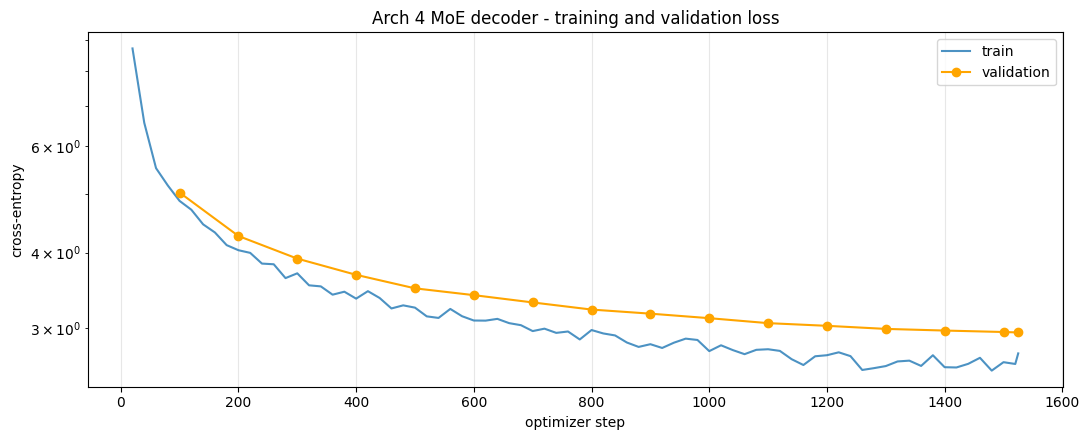

final val loss 2.9510 | perplexity 19.13


In [25]:
import matplotlib.pyplot as plt

train_pts, val_pts = [], []
with open(C.LOG_PATH) as f:
    for line in f:
        r = json.loads(line)
        if "loss" in r:
            train_pts.append((r["step"], r["loss"]))
        elif "val_loss" in r:
            val_pts.append((r["step"], r["val_loss"]))

plt.figure(figsize=(11, 4.5))
plt.plot(*zip(*train_pts), label="train", alpha=0.8)
if val_pts:
    plt.plot(*zip(*val_pts), "o-", label="validation", color="orange")
plt.xlabel("optimizer step"); plt.ylabel("cross-entropy"); plt.yscale("log")
plt.title("Arch 4 MoE decoder - training and validation loss")
plt.grid(alpha=0.3); plt.legend(); plt.tight_layout()
plot_path = os.path.join(C.WORK_DIR, "loss_curve.png")
plt.savefig(plot_path, dpi=150); plt.show()
if val_pts:
    print(f"final val loss {val_pts[-1][1]:.4f} | perplexity {math.exp(val_pts[-1][1]):.2f}")

## 13. Load the trained model for generation

In [ ]:
# Which weights to generate with: "final" (end of training), "best" (lowest validation loss) or "latest" (last saved state).
# Section 13b compares them on held-out text, so you can pick by generation quality, not only validation loss.
CHOSEN_WEIGHTS = "final"

on_hub_now = set(api.list_repo_files(C.HF_MODEL_REPO, token=HF_TOKEN))
WEIGHT_FILES = {"final": (C.FINAL_PATH, "model_final.pt"),
                "best": (C.BEST_PATH, "model_best.pt"),
                "latest": (C.STATE_PATH, "training_state.pt")}
available = {}
for name, (path, remote) in WEIGHT_FILES.items():
    if not os.path.exists(path) and remote in on_hub_now and name != "latest":
        hf_hub_download(C.HF_MODEL_REPO, remote, local_dir=C.CKPT_DIR, token=HF_TOKEN)
    if os.path.exists(path):
        available[name] = path

# Which training step does each file come from? (A leftover model_final.pt from an earlier, shorter run is older than
# the latest checkpoint of a longer run that has not finished yet - this makes that visible.)
def file_step(path):
    return torch.load(path, map_location="cpu", mmap=True).get("step", "unknown (older file)")
steps_of = {name: file_step(path) for name, path in available.items()}
print("Weights found (training step each one comes from):", steps_of)
if "final" in available and "latest" in available and steps_of["final"] == steps_of["latest"]:
    available.pop("latest")                       # identical, no need to evaluate it twice
elif "final" in available and "latest" in available:
    print("NOTE: model_final.pt is not from the latest checkpoint - it is probably left over from an earlier run. "
          "Set CHOSEN_WEIGHTS = 'latest' to use the newest weights.")
if CHOSEN_WEIGHTS not in available:
    CHOSEN_WEIGHTS = next(k for k in ("final", "best", "latest") if k in available)
    print("Requested weights not available, using:", CHOSEN_WEIGHTS)

device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

def load_model(path):
    blob = torch.load(path, map_location="cpu")
    model = M.MoEGPT(M.ModelConfig(**blob["model_cfg"]))
    model.load_state_dict({k: v.float() for k, v in blob["model"].items()})
    del blob
    return model.to(device).eval()

gen_model = load_model(available[CHOSEN_WEIGHTS])
gc.collect()
print(f"Generating with '{CHOSEN_WEIGHTS}' weights on {device}: {gen_model.num_params() / 1e6:.1f}M parameters")

## 13b. Local evaluation on held-out text (mirrors the official metrics)
The competition scores a 128-word continuation of a 512-word prompt with BERTScore F1 (primary), ROUGE-L F1 and BLEU-4.
Here we build the *same kind of task* from the validation documents (never trained on): first 512 words = prompt,
next 128 words = reference. ROUGE-L and BLEU-4 are implemented below; BERTScore is optional (it downloads roberta-large).
Use this to compare checkpoints by generation quality, not just validation loss.

In [27]:
import numpy as np

def lcs_len(a, b):
    prev = [0] * (len(b) + 1)
    for x in a:
        cur = [0]
        for j, y in enumerate(b):
            cur.append(prev[j] + 1 if x == y else max(prev[j + 1], cur[j]))
        prev = cur
    return prev[-1]

def rouge_l_f1(ref, hyp):
    r, h = ref.split(), hyp.split()
    if not r or not h:
        return 0.0
    lcs = lcs_len(r, h)
    if lcs == 0:
        return 0.0
    p, rec = lcs / len(h), lcs / len(r)
    return 2 * p * rec / (p + rec)

def bleu4(ref, hyp):
    r, h = ref.split(), hyp.split()
    if not h:
        return 0.0
    log_p = 0.0
    for n in range(1, 5):
        ref_grams, hyp_grams = {}, {}
        for i in range(len(r) - n + 1):
            g = tuple(r[i:i + n]); ref_grams[g] = ref_grams.get(g, 0) + 1
        for i in range(len(h) - n + 1):
            g = tuple(h[i:i + n]); hyp_grams[g] = hyp_grams.get(g, 0) + 1
        overlap = sum(min(c, ref_grams.get(g, 0)) for g, c in hyp_grams.items())
        total = max(1, sum(hyp_grams.values()))
        log_p += math.log((overlap + 1) / (total + 1)) / 4          # add-one smoothing
    brevity = 1.0 if len(h) >= len(r) else math.exp(1 - len(r) / len(h))
    return brevity * math.exp(log_p)

# rebuild a few full documents from the validation token file (documents are separated by <eos>)
val_tokens = np.fromfile(C.VAL_BIN, dtype=np.uint16)
cuts = np.flatnonzero(val_tokens == tok.eos_id)
eval_prompts, eval_refs = [], []
for a, b in zip(cuts[:-1], cuts[1:]):                              # skip the last, possibly truncated, document
    words = tok.decode(val_tokens[a + 1:b].tolist()).split()
    if len(words) >= 512 + C.TARGET_WORDS:
        eval_prompts.append(" ".join(words[:512]))
        eval_refs.append(" ".join(words[512:512 + C.TARGET_WORDS]))
    if len(eval_prompts) >= C.N_LOCAL_EVAL:
        break
print(f"{len(eval_prompts)} held-out documents with 512-word prompts")

def run_generation(model, prompt_texts):
    room = C.MAX_SEQ_LEN - C.MAX_NEW_TOKENS
    ids = [tok.encode(t) for t in prompt_texts]
    ids = [x[-room:] if len(x) > room else [tok.eos_id] + x for x in ids]
    outs = []
    for b in range(0, len(ids), C.GEN_BATCH):
        with torch.autocast("cuda", dtype=torch.float16, enabled=device.type == "cuda"):
            outs += M.generate(model, ids[b:b + C.GEN_BATCH], tok, max_new_tokens=C.MAX_NEW_TOKENS,
                               target_words=C.TARGET_WORDS, temperature=C.GEN_TEMPERATURE,
                               top_k=C.GEN_TOP_K, top_p=C.GEN_TOP_P)
    return outs

if eval_prompts:
    results = {}
    for name, path in available.items():
        mdl = gen_model if name == CHOSEN_WEIGHTS else load_model(path)
        hyps = run_generation(mdl, eval_prompts)
        rl = [rouge_l_f1(r, h) for r, h in zip(eval_refs, hyps)]
        bl = [bleu4(r, h) for r, h in zip(eval_refs, hyps)]
        results[name] = (float(np.mean(rl)), float(np.mean(bl)), hyps)
        print(f"{name:7s} | ROUGE-L F1 {results[name][0]:.4f} | BLEU-4 {results[name][1]:.4f} | "
              f"words/prediction {np.mean([len(h.split()) for h in hyps]):.0f}")
        if mdl is not gen_model:
            del mdl
            gc.collect()
            torch.cuda.empty_cache()
    hyps = results[CHOSEN_WEIGHTS][2]              # the rest of this section looks at the chosen weights

    RUN_BERTSCORE = False        # set True to also compute the official primary metric (needs: pip install bert_score)
    if RUN_BERTSCORE:
        from bert_score import score as bert_score
        _, _, f1 = bert_score(hyps, eval_refs, lang="en", model_type="roberta-large")
        print(f"BERTScore F1: {f1.mean().item():.4f}")
    print("\nSample prompt tail :", eval_prompts[0].split()[-25:])
    print("Sample reference   :", eval_refs[0][:200])
    print("Sample generation  :", hyps[0][:200])

48 held-out documents with 512-word prompts
final   | ROUGE-L F1 0.2915 | BLEU-4 0.1673 | words/prediction 128
best    | ROUGE-L F1 0.2832 | BLEU-4 0.1621 | words/prediction 128

Sample prompt tail : ['and', 'Validation)', 'Act,', '1996.', '(2)', 'It', 'shall', 'come', 'into', 'force', 'at', 'once.', '2.', 'Amendment', 'of', 'Zonal', 'Regulations', 'appended', 'to', 'the', 'Outline', 'Development', 'Plan.', '-', 'Notwithstanding']
Sample reference   : anything contained in any judgement, decree or order of any court, tribunal or any other authority, Zonal regulations appended to the Outline Development Plan of the Bangalore City Planning Area made 
Sample generation  : anything contained in the Code of Civil Procedure, 1908 (5 of 1908) the Andhra Pradesh Municipal Corporation (Amendment) Act, 2004 (Maharashtra Act 25 of 2004) shall come into force on the date of its


## 14. Generate predictions for the test set
Batched, latent-KV-cached, drop-free-MoE sampling (temperature / top-k / top-p from `config.py`). Prompts are sorted by length so padding stays small.

In [28]:
test_path = hf_hub_download(C.HF_DATASET_REPO, C.TEST_FILE, repo_type="dataset", token=HF_TOKEN)
with open(test_path, "r", encoding="utf-8") as f:
    test_data = json.load(f)
print("Test examples:", len(test_data))

room = C.MAX_SEQ_LEN - C.MAX_NEW_TOKENS
def make_prompt(text):
    ids = tok.encode(text)
    return ids[-room:] if len(ids) > room else [tok.eos_id] + ids

keys = list(test_data.keys())
n_trunc = sum(len(tok.encode(test_data[k]["text"])) > room for k in keys)
print(f"{n_trunc}/{len(keys)} prompts exceed {room} tokens and will be cut from the left (the doc says prompts are 512 words)")
prompts = {k: make_prompt(test_data[k]["text"]) for k in keys}
order = sorted(keys, key=lambda k: len(prompts[k]))

PRED_PATH = os.path.join(C.WORK_DIR, "prediction.json")
predictions = {}
t0 = time.time()
for b in range(0, len(order), C.GEN_BATCH):
    chunk = order[b:b + C.GEN_BATCH]
    with torch.autocast("cuda", dtype=torch.float16, enabled=device.type == "cuda"):
        outs = M.generate(gen_model, [prompts[k] for k in chunk], tok,
                          max_new_tokens=C.MAX_NEW_TOKENS, target_words=C.TARGET_WORDS,
                          temperature=C.GEN_TEMPERATURE, top_k=C.GEN_TOP_K, top_p=C.GEN_TOP_P)
    for k, text in zip(chunk, outs):
        predictions[str(k)] = {"text": text}
    done = len(predictions)
    if (b // C.GEN_BATCH) % 5 == 0 or done == len(order):
        print(f"  {done}/{len(order)} | {time.time() - t0:.0f}s elapsed")
    if (b // C.GEN_BATCH) % 20 == 0:                       # partial save in case the session dies
        with open(PRED_PATH, "w", encoding="utf-8") as f:
            json.dump(predictions, f, ensure_ascii=False)

predictions = {str(k): predictions[str(k)] for k in keys}  # original order
print("Generation complete:", len(predictions), "predictions")

test.json:   0%|          | 0.00/3.03M [00:00<?, ?B/s]

Test examples: 1000
0/1000 prompts exceed 1664 tokens and will be cut from the left (the doc says prompts are 512 words)
  8/1000 | 5s elapsed
  48/1000 | 33s elapsed
  88/1000 | 63s elapsed
  128/1000 | 92s elapsed
  168/1000 | 130s elapsed
  208/1000 | 157s elapsed
  248/1000 | 191s elapsed
  288/1000 | 218s elapsed
  328/1000 | 245s elapsed
  368/1000 | 278s elapsed
  408/1000 | 308s elapsed
  448/1000 | 335s elapsed
  488/1000 | 370s elapsed
  528/1000 | 406s elapsed
  568/1000 | 442s elapsed
  608/1000 | 474s elapsed
  648/1000 | 500s elapsed
  688/1000 | 534s elapsed
  728/1000 | 570s elapsed
  768/1000 | 597s elapsed
  808/1000 | 633s elapsed
  848/1000 | 662s elapsed
  888/1000 | 694s elapsed
  928/1000 | 728s elapsed
  968/1000 | 764s elapsed
  1000/1000 | 794s elapsed
Generation complete: 1000 predictions


## 15. Save predictions and build the submission zip

In [29]:
with open(PRED_PATH, "w", encoding="utf-8") as f:
    json.dump(predictions, f, ensure_ascii=False, indent=2)

SUBMISSION_ZIP = os.path.join(C.WORK_DIR, "submission.zip")
with zipfile.ZipFile(SUBMISSION_ZIP, "w", compression=zipfile.ZIP_DEFLATED) as z:
    z.write(PRED_PATH, arcname="prediction.json")
print(f"Wrote {SUBMISSION_ZIP} ({os.path.getsize(SUBMISSION_ZIP) / 1024:.1f} KB)")

# --- submission self-check (the checklist in the competition document, Section 19)
official_ids = set(map(str, test_data.keys()))
assert set(predictions) == official_ids,     f"ID mismatch: missing {len(official_ids - set(predictions))}, unknown {len(set(predictions) - official_ids)}"
assert all(isinstance(v.get("text"), str) and v["text"].strip() for v in predictions.values()), "empty prediction text"
n_words = [len(v["text"].split()) for v in predictions.values()]
print(f"ID check passed ({len(predictions)} ids). Words per prediction: min {min(n_words)} / mean {np.mean(n_words):.0f} / max {max(n_words)}")
if min(n_words) < C.TARGET_WORDS:
    print(f"WARNING: {sum(w < C.TARGET_WORDS for w in n_words)} predictions are shorter than {C.TARGET_WORDS} words")
with zipfile.ZipFile(SUBMISSION_ZIP) as z:
    assert z.namelist() == ["prediction.json"], f"zip must contain only prediction.json at its root, got {z.namelist()}"
print("Zip structure OK: prediction.json at the archive root.")

for k in list(predictions)[:3]:
    words = predictions[k]["text"].split()
    print(f"\nExample {k} ({len(words)} words):\n{predictions[k]['text'][:300]}...")

# keep a copy on the hub too
api.upload_file(path_or_fileobj=SUBMISSION_ZIP, path_in_repo="submission.zip", repo_id=C.HF_MODEL_REPO, token=HF_TOKEN)
api.upload_file(path_or_fileobj=plot_path, path_in_repo="loss_curve.png", repo_id=C.HF_MODEL_REPO, token=HF_TOKEN)
print("Submission and loss curve pushed to", C.HF_MODEL_REPO)

Wrote /kaggle/working/arch4/submission.zip (183.0 KB)
ID check passed (1000 ids). Words per prediction: min 17 / mean 128 / max 128
Zip structure OK: prediction.json at the archive root.

Example 1 (128 words):
not necessary to notice the observations made by the High Court as to the interpretation of the rule. As rightly pointed out by the learned counsel for the State that the High Court has rightly rejected the application of the respondent, we do not find any reason to interfere with the decision of th...

Example 2 (128 words):
for further investigation as per the guidelines contained in Section 190 (3) Cr.P.C. We have also seen the facts which have come out from the complaint filed by the accused and as far as the investigation is concerned, it is apparent that in view of the above, the complaint filed by the complainant ...

Example 3 (128 words):
for such action. (6) The police officer shall, in his discretion, keep the seal of the Police Officer and shall, after the arrest of 

Processing Files (0 / 0): |          |  0.00B /  0.00B            

New Data Upload: |          |  0.00B /  0.00B            

Submission and loss curve pushed to D-240357/legal-arch4-moe
